In [1]:
from config_path import add_to_sys_path
add_to_sys_path()  # Call the function to add path

import numpy as np
from sympy.physics.wigner import wigner_3j,wigner_6j
import sympy as sy
from numpy import linalg as LA
from IPython.display import Latex,display
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
sns.set_palette('terrain')
from Energy_Levels import MoleculeLevels
from molecule_parameters import get_molecule_params
np.set_printoptions(precision=5, suppress=True)

Added C:\Users\Arian\Code\Molecule-Structure\Source Code to sys.path


In [2]:
X000_173 = MoleculeLevels.initialize_state('YbOH','X','000',[0,1,2,3,4],fermion_or_boson='fermion',isotope='173',M_sublevels='none',I_nuclei=[5/2,1/2],S_electron=1/2,round=6)

No projection values of J provided, using minimal projection 0.5 as default
Cannot construct decoupled basis without M values


In [3]:
# port: H_odd_A now reads A-state H hyperfine h1/2H, dH, which the odd-YbOH A000 dicts lack (KeyError).
# 0 reproduces the Hamiltonian this notebook was run with (the H terms were added in bacb463, 2026-05-07).
A000_173 = MoleculeLevels.initialize_state('YbOH','A','000',[1,2,3,4],fermion_or_boson='fermion',isotope='173',params={**get_molecule_params('YbOH','173A','000','fermion'),'h1/2H':0,'dH':0},M_sublevels='none',I_nuclei=[5/2,1/2],S_electron=1/2,round=6)

No projection values of J provided, using minimal projection 0.5 as default
Cannot construct decoupled basis without M values


In [4]:
evals, evecs = A000_173.eigensystem(0,0.0000,order=True,method='numpy')

In [5]:
from Energy_Levels import XA_branching_ratios

In [6]:
def select_N(N,state):
    idx = []
    N = np.array(N)
    for i,qN in enumerate(state.q_numbers['N']):
        for _N in N:
            if qN == _N:
                idx.append(i)
    return np.array(idx)

def select_J(J,state):
    idx = []
    J = np.array(J)
    for i,qJ in enumerate(state.q_numbers['J']):
        for _J in J:
            if qJ == _J:
                idx.append(i)
    return np.array(idx)

In [7]:
J_idx = select_J([0.5,1.5,2.5],A000_173)

In [8]:
for i in J_idx:
    display(Latex(A000_173.gen_state_str(0,basis=None,label_q=None,thresh=0.0001,show_coeff=True,new_line=False,round=None)))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

... (36 outputs left out)

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

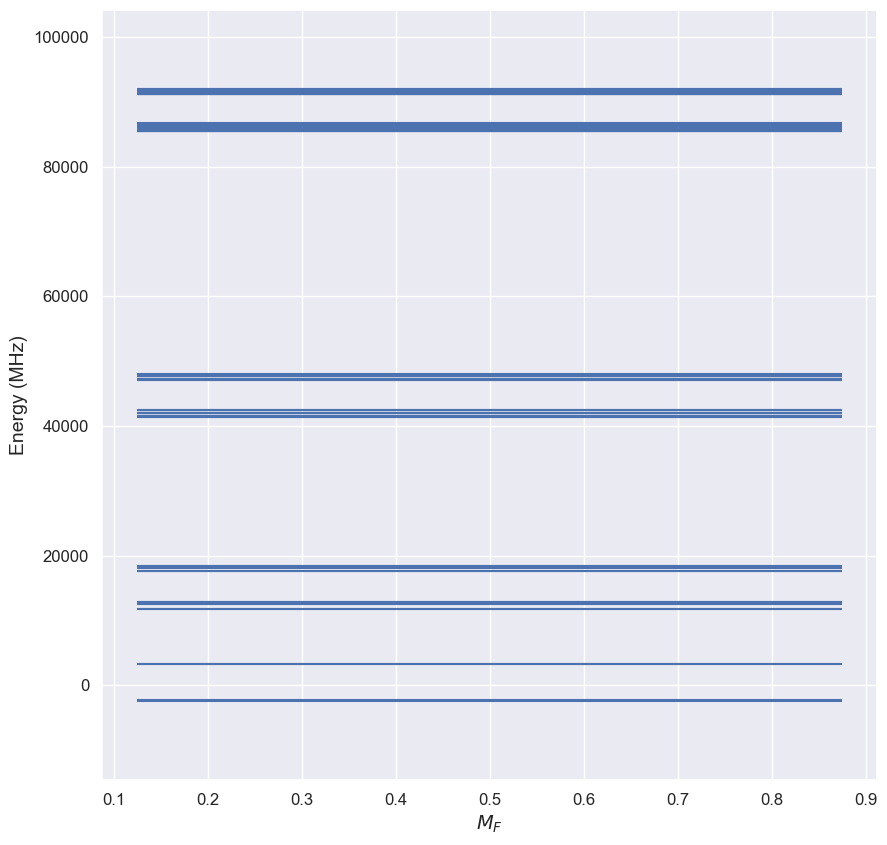

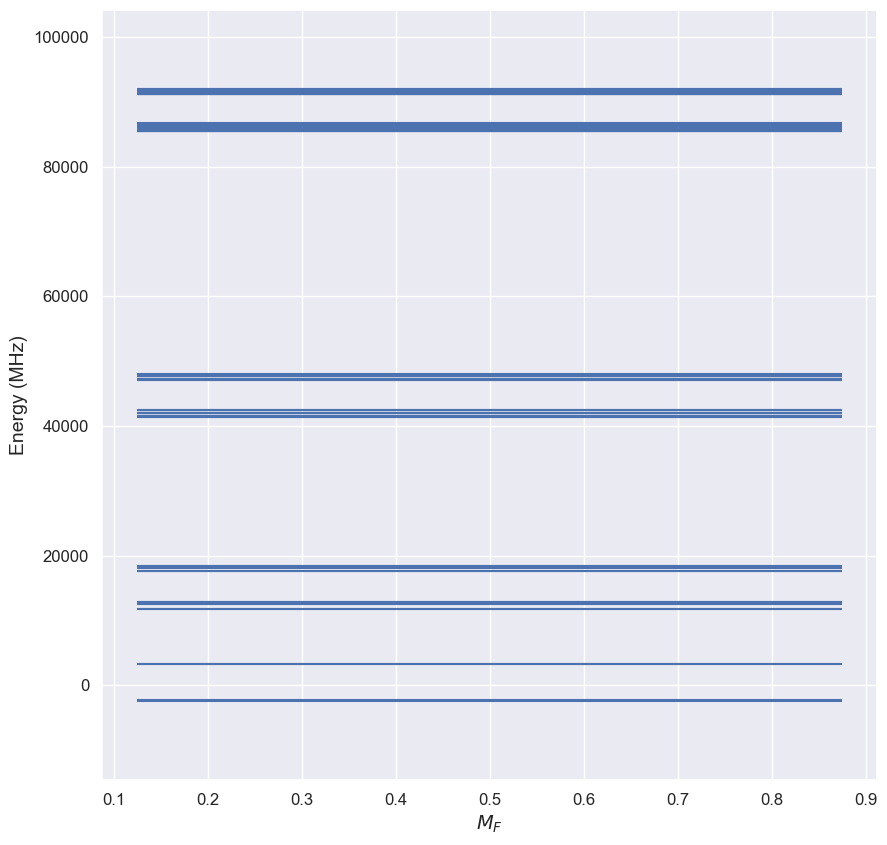

In [9]:
N_idx = select_N([0,1,2,3],X000_173)  # port: N_idx was never defined in this notebook; N=0-3 read off the saved figure
X000_173.display_levels(0,0,'G',idx=N_idx)